In [1]:
import sys, os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, f1_score

sys.path.append(os.path.abspath('..'))
from src.models import MLP
from src.train import treinar

# Cria pastas exigidas pelo repositório
os.makedirs('../logs', exist_ok=True)
os.makedirs('../reports/figures', exist_ok=True)
os.makedirs('../reports/tables', exist_ok=True)

SEMENTES = [42, 123, 456]

def fixar_sementes(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def criar_otimizador(nome, params, lr, wd):
    if nome == "SGD":
        return torch.optim.SGD(params, lr=lr, weight_decay=wd)
    elif nome == "SGD_momentum":
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=wd)
    elif nome == "RMSprop":
        return torch.optim.RMSprop(params, lr=lr, weight_decay=wd)
    elif nome == "Adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    elif nome == "AdamW":
        return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    raise ValueError(f"Otimizador desconhecido: {nome}")

# Carrega APENAS os conjuntos de treino (teste não é tocado aqui!)
df_reg = pd.read_csv('../data/processed/train_regression.csv')
X_r = df_reg.drop(columns=['Mental_Wellbeing_Score']).values
y_r = df_reg['Mental_Wellbeing_Score'].values
Xr_tr, Xr_va, yr_tr, yr_va = train_test_split(X_r, y_r, test_size=0.2, random_state=42)

sc_Xr = StandardScaler().fit(Xr_tr)
sc_yr = StandardScaler().fit(yr_tr.reshape(-1, 1))
REG_DATA = (
    torch.tensor(sc_Xr.transform(Xr_tr), dtype=torch.float32),
    torch.tensor(sc_yr.transform(yr_tr.reshape(-1, 1)), dtype=torch.float32),
    torch.tensor(sc_Xr.transform(Xr_va), dtype=torch.float32),
    torch.tensor(sc_yr.transform(yr_va.reshape(-1, 1)), dtype=torch.float32),
    yr_tr, yr_va, sc_yr
)

df_clf = pd.read_csv('../data/processed/train_classification.csv')
X_c = df_clf.drop(columns=['Addiction_Level']).values
y_c = df_clf['Addiction_Level'].values
Xc_tr, Xc_va, yc_tr, yc_va = train_test_split(X_c, y_c, test_size=0.2, random_state=42, stratify=y_c)

sc_Xc = StandardScaler().fit(Xc_tr)
CLF_DATA = (
    torch.tensor(sc_Xc.transform(Xc_tr), dtype=torch.float32),
    torch.tensor(yc_tr, dtype=torch.long),
    torch.tensor(sc_Xc.transform(Xc_va), dtype=torch.float32),
    torch.tensor(yc_va, dtype=torch.long),
    yc_tr, yc_va, None
)

print(f"Regressão -> Treino: {Xr_tr.shape}, Val: {Xr_va.shape}")
print(f"Classificação -> Treino: {Xc_tr.shape}, Val: {Xc_va.shape}")

Regressão -> Treino: (960, 29), Val: (240, 29)
Classificação -> Treino: (960, 29), Val: (240, 29)


In [2]:
def avaliar_config(tarefa, cfg, sementes=SEMENTES):
    X_tr, y_tr, X_va, y_va, y_tr_orig, y_va_orig, sc_y = REG_DATA if tarefa == "regressao" else CLF_DATA
    out_dim = 1 if tarefa == "regressao" else 4
    loss_fn = nn.MSELoss() if tarefa == "regressao" else nn.CrossEntropyLoss()

    m_tr_list, m_va_list, epocas_list, tempos_list = [], [], [], []
    n_params = 0

    for seed in sementes:
        fixar_sementes(seed)
        bs = min(cfg["batch_size"], len(X_tr))
        dl_tr = DataLoader(TensorDataset(X_tr, y_tr), batch_size=bs, shuffle=True)
        dl_va = DataLoader(TensorDataset(X_va, y_va), batch_size=64, shuffle=False)

        modelo = MLP(
            in_dim=X_tr.shape[1], out_dim=out_dim,
            hidden=cfg["hidden"], activation=cfg["activation"], dropout=cfg["dropout"]
        )
        n_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
        otim = criar_otimizador(cfg["opt"], modelo.parameters(), cfg["lr"], cfg["weight_decay"])

        t0 = time.perf_counter()
        hist = treinar(modelo, dl_tr, dl_va, loss_fn, otim, n_epocas=200, paciencia=20)
        dt = time.perf_counter() - t0

        modelo.eval()
        with torch.inference_mode():
            pred_tr = modelo(X_tr).numpy()
            pred_va = modelo(X_va).numpy()

        # Proteção contra divergência (ex: lr muito alto -> NaN/Inf)
        if np.isnan(pred_va).any() or np.isinf(pred_va).any():
            m_tr = np.nan
            m_va = np.nan
        elif tarefa == "regressao":
            p_tr_orig = sc_y.inverse_transform(pred_tr).ravel()
            p_va_orig = sc_y.inverse_transform(pred_va).ravel()
            m_tr = root_mean_squared_error(y_tr_orig, p_tr_orig)
            m_va = root_mean_squared_error(y_va_orig, p_va_orig)
        else:
            m_tr = f1_score(y_tr_orig, pred_tr.argmax(axis=1), average="macro")
            m_va = f1_score(y_va_orig, pred_va.argmax(axis=1), average="macro")

        m_tr_list.append(m_tr)
        m_va_list.append(m_va)
        epocas_list.append(len(hist["val"]))
        tempos_list.append(dt)

    tr_med, tr_std = np.nanmean(m_tr_list), np.nanstd(m_tr_list)
    va_med, va_std = np.nanmean(m_va_list), np.nanstd(m_va_list)
    # Gap: em classificação (maior é melhor) = treino - val; em regressão (menor é melhor) = val - treino
    gap = (va_med - tr_med) if tarefa == "regressao" else (tr_med - va_med)

    return {
        "Params": n_params,
        "Metrica_treino_media": tr_med,
        "Metrica_treino_std": tr_std,
        "Metrica_val_media": va_med,
        "Metrica_val_std": va_std,
        "Gap_treino_val": gap,
        "Epoca_parada_media": np.mean(epocas_list),
        "Tempo_medio_s": np.mean(tempos_list)
    }

BASELINE = {
    "hidden": [32, 32], "activation": "ReLU", "opt": "Adam",
    "lr": 1e-3, "batch_size": 32, "dropout": 0.0, "weight_decay": 0.0
}

ESTUDOS = {
    "Neuronios": [(str(h), {"hidden": [h, h]}) for h in [8, 16, 32, 64, 128]],
    "Camadas": [(str(c), {"hidden": [32] * c}) for c in [1, 2, 3, 5]],
    "Ativacao": [(a, {"activation": a}) for a in ["ReLU", "LeakyReLU", "Tanh", "Sigmoid", "GELU"]],
    "Otimizador": [(o, {"opt": o}) for o in ["SGD", "SGD_momentum", "RMSprop", "Adam", "AdamW"]],
    "Learning_Rate": [(str(lr), {"lr": lr}) for lr in [1e-4, 1e-3, 1e-2, 1e-1]],
    "Batch_Size": [(str(bs), {"batch_size": bs}) for bs in [8, 32, 128, 512]],
    "Dropout": [(str(d), {"dropout": d}) for d in [0.0, 0.1, 0.3, 0.5]],
    "Weight_Decay": [(str(wd), {"weight_decay": wd}) for wd in [0.0, 1e-5, 1e-4, 1e-3, 1e-2]],
}

In [3]:
registros = []

for tarefa in ["regressao", "classificacao"]:
    print(f"\n=== Rodando Estudo de Hiperparâmetros: {tarefa.upper()} ===")
    for hp_nome, variacoes in ESTUDOS.items():
        for valor_str, alteracao in variacoes:
            cfg = {**BASELINE, **alteracao}
            res = avaliar_config(tarefa, cfg)
            registros.append({
                "Tarefa": tarefa,
                "Hiperparametro": hp_nome,
                "Valor": valor_str,
                **res
            })
        print(f"  [OK] {hp_nome}")

df_logs = pd.DataFrame(registros)
df_logs.to_csv('../logs/hiperparametros.csv', index=False)
print("\nLogs salvos em ../logs/hiperparametros.csv")
display(df_logs.head(10))


=== Rodando Estudo de Hiperparâmetros: REGRESSAO ===
  [OK] Neuronios
  [OK] Camadas
  [OK] Ativacao
  [OK] Otimizador
  [OK] Learning_Rate
  [OK] Batch_Size
  [OK] Dropout
  [OK] Weight_Decay

=== Rodando Estudo de Hiperparâmetros: CLASSIFICACAO ===
  [OK] Neuronios
  [OK] Camadas
  [OK] Ativacao
  [OK] Otimizador
  [OK] Learning_Rate
  [OK] Batch_Size
  [OK] Dropout
  [OK] Weight_Decay

Logs salvos em ../logs/hiperparametros.csv


,Tarefa,Hiperparametro,Valor,Params,Metrica_treino_media,Metrica_treino_std,Metrica_val_media,Metrica_val_std,Gap_treino_val,Epoca_parada_media,Tempo_medio_s
0,regressao,Neuronios,8,321,0.421483,0.072907,0.488362,0.057652,0.066879,97.000000,4.878814
1,regressao,Neuronios,16,769,0.373034,0.095737,0.533007,0.027262,0.159973,72.666667,3.309126
2,regressao,Neuronios,32,2049,0.422853,0.080649,0.557733,0.013892,0.134880,39.000000,1.795706
3,regressao,Neuronios,64,6145,0.399289,0.063955,0.567035,0.004635,0.167746,32.333333,1.668469
4,regressao,Neuronios,128,20481,0.280804,0.136122,0.558416,0.013305,0.277612,33.666667,1.886708
5,regressao,Camadas,1,993,0.276762,0.008184,0.513942,0.010585,0.237180,101.000000,3.844424
6,regressao,Camadas,2,2049,0.422853,0.080649,0.557733,0.013892,0.134880,39.000000,1.676803
7,regressao,Camadas,3,3105,0.412421,0.060805,0.576930,0.010764,0.164509,35.000000,1.740249
8,regressao,Camadas,5,5217,0.437689,0.092823,0.571885,0.010656,0.134196,31.666667,2.068162
9,regressao,Ativacao,ReLU,2049,0.422853,0.080649,0.557733,0.013892,0.134880,39.000000,2.683979


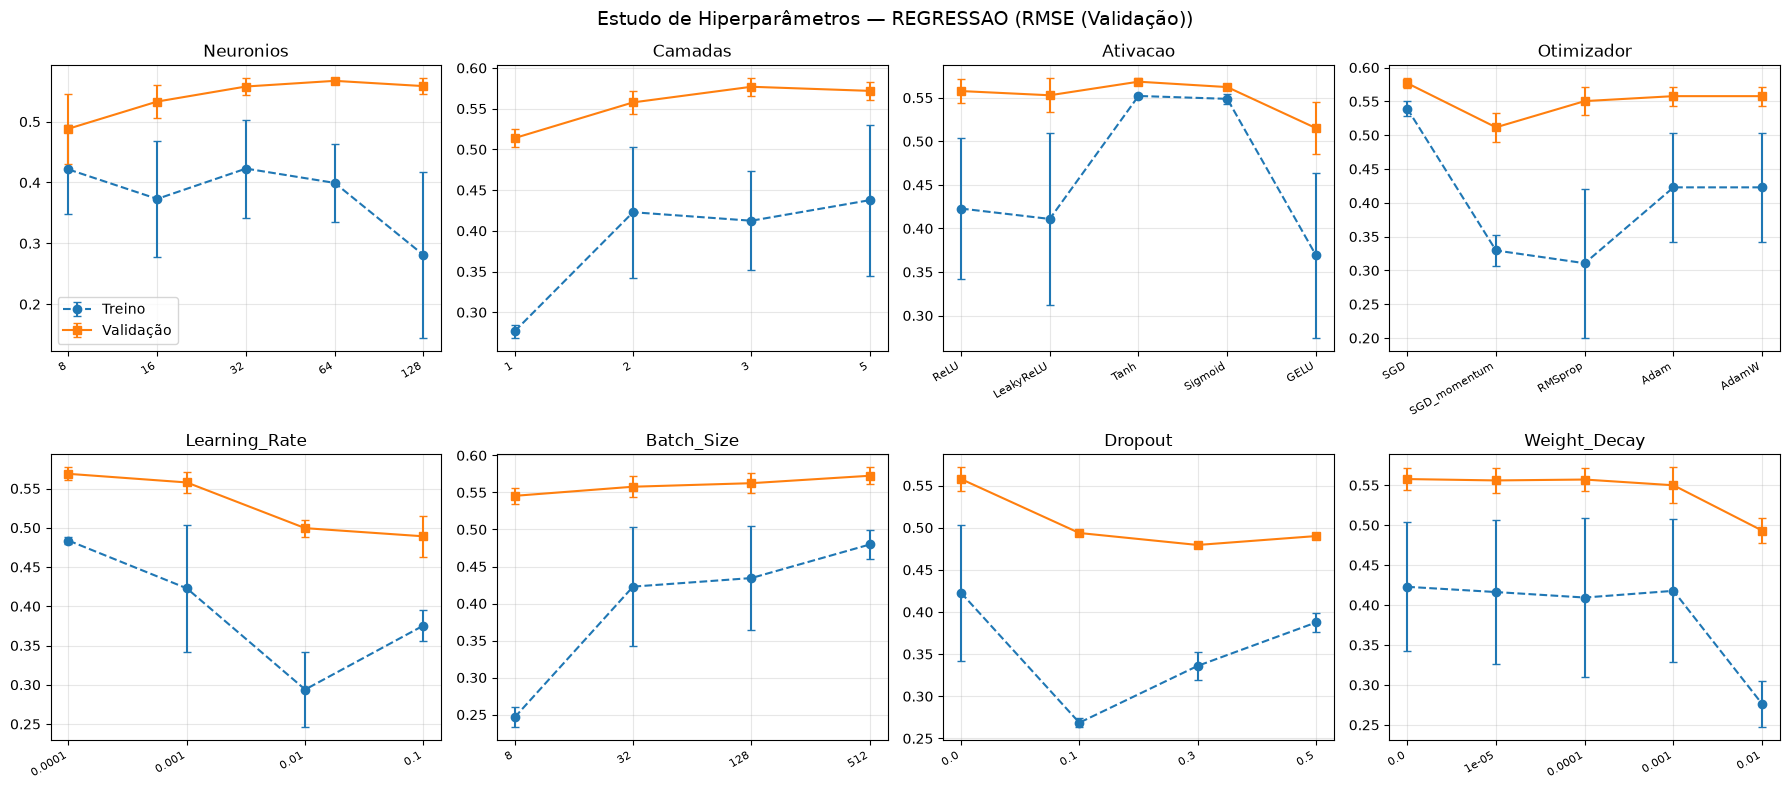

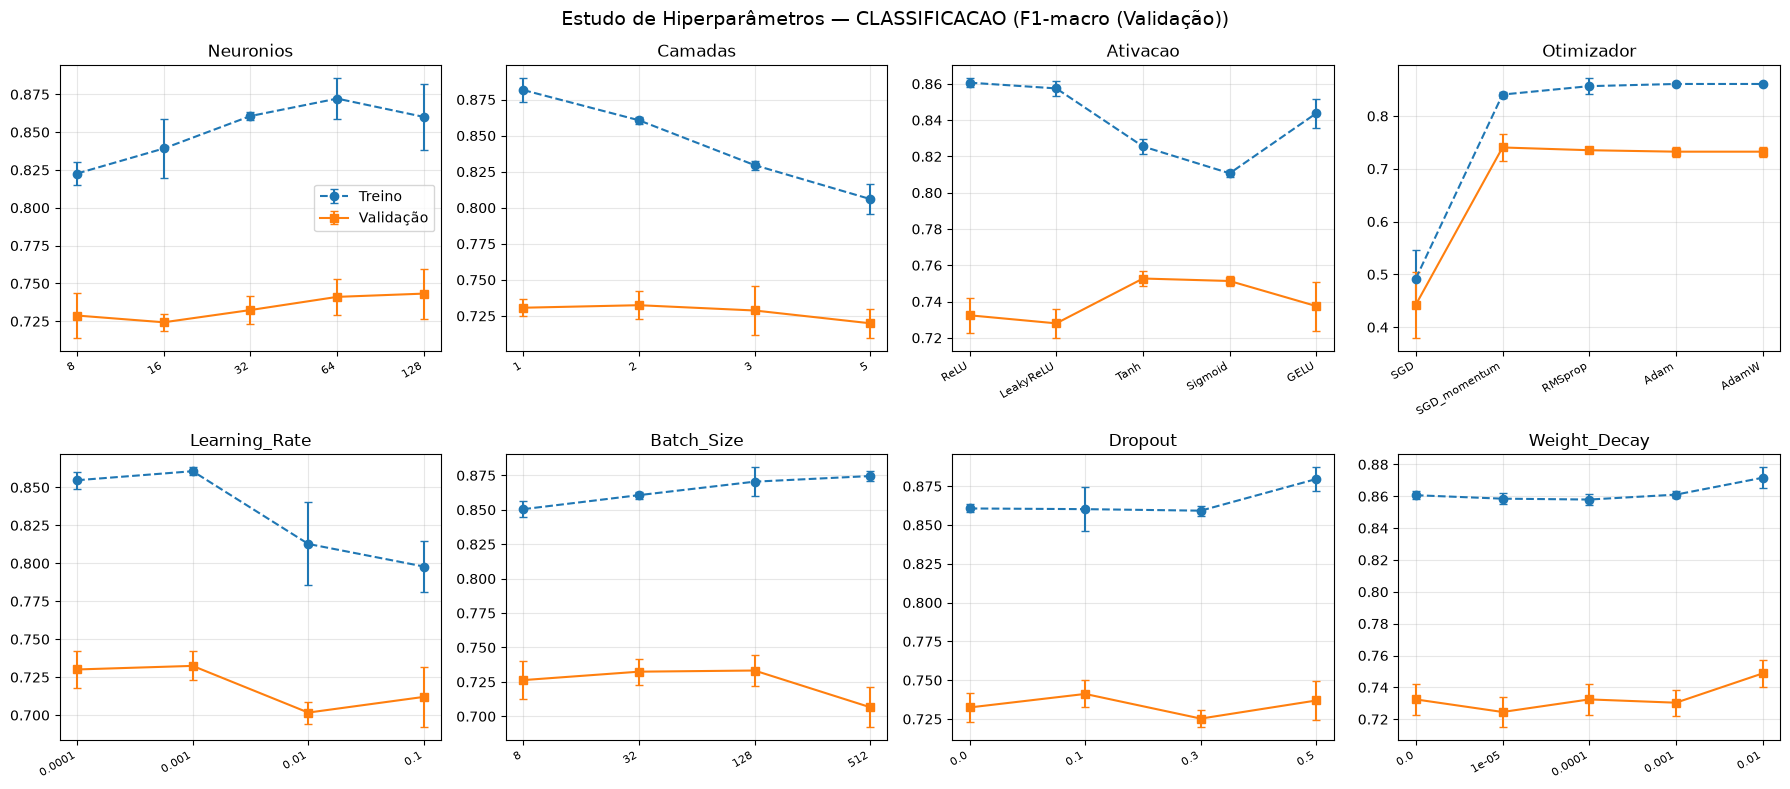

,Tarefa,Hiperparametro,Melhor_Valor,Impacto_Max_Min,Desvio_Medio_Sementes,Efeito_Real
14,classificacao,Otimizador,SGD_momentum,0.29777,0.02245,Sim
12,classificacao,Learning_Rate,0.001,0.03076,0.01228,Sim
9,classificacao,Batch_Size,128,0.02666,0.01224,Sim
8,classificacao,Ativacao,Tanh,0.02471,0.00762,Sim
15,classificacao,Weight_Decay,0.01,0.02424,0.00909,Sim
13,classificacao,Neuronios,128,0.01896,0.01161,Sim
11,classificacao,Dropout,0.1,0.01589,0.00904,Sim
10,classificacao,Camadas,2,0.01253,0.01054,Sim
4,regressao,Learning_Rate,0.1,0.07959,0.01488,Sim
5,regressao,Neuronios,8,0.07867,0.02335,Sim


In [4]:
for tarefa, metrica_label in [("regressao", "RMSE (Validação)"), ("classificacao", "F1-macro (Validação)")]:
    sub_t = df_logs[df_logs["Tarefa"] == tarefa]
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    axes = axes.ravel()

    for ax, hp_nome in zip(axes, ESTUDOS.keys()):
        d = sub_t[sub_t["Hiperparametro"] == hp_nome]
        x = np.arange(len(d))
        ax.errorbar(x, d["Metrica_treino_media"], yerr=d["Metrica_treino_std"], marker='o', linestyle='--', label="Treino", capsize=3)
        ax.errorbar(x, d["Metrica_val_media"], yerr=d["Metrica_val_std"], marker='s', label="Validação", capsize=3)
        ax.set_xticks(x)
        ax.set_xticklabels(d["Valor"], rotation=30, ha='right', fontsize=8)
        ax.set_title(hp_nome)
        ax.grid(alpha=0.3)

    axes[0].legend()
    fig.suptitle(f"Estudo de Hiperparâmetros — {tarefa.upper()} ({metrica_label})", fontsize=14)
    plt.tight_layout()
    plt.savefig(f'../reports/figures/hiperparametros_{tarefa}.png', dpi=150)
    plt.show()

# Tabela de Sensibilidade (impacto = max - min na validação)
sens_rows = []
for tarefa in ["regressao", "classificacao"]:
    sub_t = df_logs[df_logs["Tarefa"] == tarefa]
    for hp_nome, grp in sub_t.groupby("Hiperparametro"):
        valid = grp["Metrica_val_media"].dropna()
        impacto = valid.max() - valid.min()
        std_medio = grp["Metrica_val_std"].mean()
        melhor_val = grp.loc[valid.idxmin() if tarefa == "regressao" else valid.idxmax(), "Valor"]
        sens_rows.append({
            "Tarefa": tarefa,
            "Hiperparametro": hp_nome,
            "Melhor_Valor": melhor_val,
            "Impacto_Max_Min": round(impacto, 5),
            "Desvio_Medio_Sementes": round(std_medio, 5),
            "Efeito_Real": "Sim" if impacto > std_medio else "Desprezível (<= std)"
        })

df_sens = pd.DataFrame(sens_rows).sort_values(["Tarefa", "Impacto_Max_Min"], ascending=[True, False])
df_sens.to_csv('../reports/tables/sensibilidade_hiperparametros.csv', index=False)
display(df_sens)

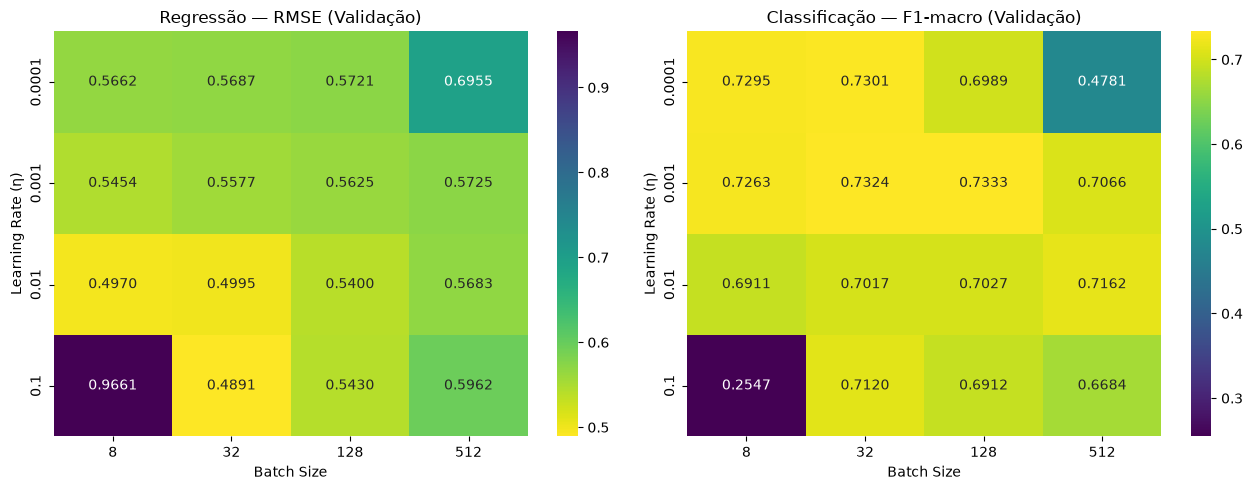

In [5]:
lrs = [1e-4, 1e-3, 1e-2, 1e-1]
batches = [8, 32, 128, 512]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, tarefa, titulo, cmap in [
    (axes[0], "regressao", "Regressão — RMSE (Validação)", "viridis_r"),
    (axes[1], "classificacao", "Classificação — F1-macro (Validação)", "viridis")
]:
    matriz = np.zeros((len(lrs), len(batches)))
    for i, lr in enumerate(lrs):
        for j, bs in enumerate(batches):
            cfg = {**BASELINE, "lr": lr, "batch_size": bs}
            res = avaliar_config(tarefa, cfg)
            matriz[i, j] = res["Metrica_val_media"]

    df_hm = pd.DataFrame(matriz, index=[str(x) for x in lrs], columns=[str(x) for x in batches])
    df_hm.to_csv(f'../reports/tables/heatmap_lr_batch_{tarefa}.csv')
    sns.heatmap(df_hm, annot=True, fmt=".4f", cmap=cmap, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("Batch Size")
    ax.set_ylabel("Learning Rate (η)")

plt.tight_layout()
plt.savefig('../reports/figures/heatmap_lr_batch.png', dpi=150)
plt.show()

In [6]:
espaco_busca = {
    "hidden": [[16, 16], [32, 32], [64, 64], [64, 32], [128, 64]],
    "activation": ["ReLU", "LeakyReLU", "Tanh", "GELU"],
    "opt": ["Adam", "AdamW", "RMSprop"],
    "lr": [5e-4, 1e-3, 3e-3, 5e-3],
    "batch_size": [16, 32, 64, 128],
    "dropout": [0.0, 0.1, 0.2, 0.3],
    "weight_decay": [0.0, 1e-5, 1e-4, 1e-3]
}

rng = random.Random(42)
configs_rs = [{k: rng.choice(v) for k, v in espaco_busca.items()} for _ in range(20)]

for tarefa in ["regressao", "classificacao"]:
    rows = []
    for idx, cfg in enumerate(configs_rs):
        res = avaliar_config(tarefa, cfg)
        rows.append({"ID": idx, **cfg, **res})
    df_rs = pd.DataFrame(rows)98
    df_rs = df_rs.sort_values("Metrica_val_media", ascending=(tarefa == "regressao"))
    df_rs.to_csv(f'../reports/tables/busca_final_{tarefa}.csv', index=False)
    print(f"\n=== TOP 3 Random Search — {tarefa.upper()} ===")
    display(df_rs[["ID", "hidden", "activation", "opt", "lr", "batch_size", "dropout", "weight_decay", "Metrica_val_media", "Metrica_val_std"]].head(3))6


=== TOP 3 Random Search — REGRESSAO ===


,ID,hidden,activation,opt,lr,batch_size,dropout,weight_decay,Metrica_val_media,Metrica_val_std
12,12,"[32, 32]",GELU,AdamW,0.0050,32,0.2,0.00001,0.449118,0.011814
14,14,"[32, 32]",GELU,Adam,0.0005,16,0.1,0.00001,0.461705,0.011767
16,16,"[16, 16]",Tanh,RMSprop,0.0030,16,0.2,0.00100,0.461730,0.001155



=== TOP 3 Random Search — CLASSIFICACAO ===


,ID,hidden,activation,opt,lr,batch_size,dropout,weight_decay,Metrica_val_media,Metrica_val_std
5,5,"[64, 64]",Tanh,RMSprop,0.003,16,0.3,0.0000,0.770274,0.012458
16,16,"[16, 16]",Tanh,RMSprop,0.003,16,0.2,0.0010,0.764958,0.007567
11,11,"[16, 16]",Tanh,AdamW,0.003,16,0.1,0.0001,0.757677,0.003785
